# 3 · A magnet made of light: the ⅓ plateau

**Frustration on a triangle.** Put the same rule on a triangular lattice and it can't be
satisfied: on every triangle at most one atom can be excited. The best the atoms can do is
excite **one of the three sublattices**, a √3×√3 crystal with exactly ⅓ of the atoms in the
Rydberg state. In spin language that is a **magnetization plateau at m = −⅓**: over a whole
range of "field" (detuning) the magnetization stops changing.

This is the physics of the triangular-lattice Ising antiferromagnet, the model behind the
rare-earth magnet **TmMgGaO₄**, whose ⅓ plateau has been studied with Pasqal's simulators.

We use a 3×4 rhombus of 12 atoms from FRESNEL_CAN1's calibrated layout. It was chosen so
that the largest blockade-respecting pattern has exactly 4 atoms, ⅓ of 12. Then we sweep to
a series of final detunings and watch the density lock at ⅓.

In [1]:
# Setup: needs the "Python 3 [Pasqal]" kernel (qBraid environment "Pasqal (Pulser)").
import sys, json, pathlib
try:
    import pulser, qbraid
except ImportError:
    raise SystemExit('Switch the kernel to "Python 3 [Pasqal]" (Kernel > Change Kernel), '
                     'or install the environment with: qbraid envs install pasqal_js2dr3')
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np
import matplotlib.pyplot as plt
from pasqal_atoms import *
print("pulser", pulser.__version__, "| qbraid", qbraid.__version__)

pulser 1.10.0 | qbraid 0.13.1


### Where to run

| `TARGET` | Runs on | Cost | Atoms |
|---|---|---|---|
| `"local"` | exact simulation on this machine (`pulser-simulation`) | free | up to ~12 |
| `"emu"` | Pasqal's **EMU_FREE** cloud emulator, through qBraid | free | up to 12 |
| `"qpu"` | Pasqal's **FRESNEL_CAN1** neutral-atom QPU, through qBraid | per minute of QPU time | up to 100 |

The sequences are built on FRESNEL_CAN1's real device specs and calibrated layout, so the
*same* object runs on all three. Start with `"emu"`; switch to `"qpu"` only after the
emulator result looks right and you have checked the estimate below.

12 atoms, 23 blockaded bonds, at most 4 excitations (= 0.333), 18 perfect crystals
nearest-neighbour U = 55 rad/µs, next-nearest U = 2.1 rad/µs


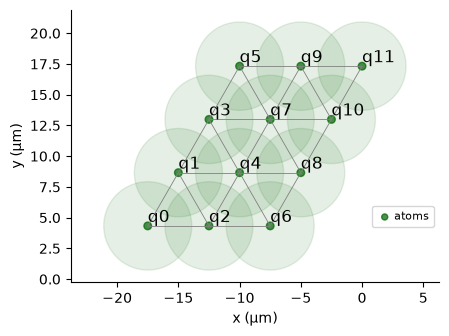

In [2]:
TARGET = "emu"
SHOTS = 500
OMEGA = 2 * np.pi * 1.0
DELTA_START = -2 * np.pi * 2.5
TRAPS = [1, 4, 7, 8, 12, 13, 16, 17, 21, 22, 26, 31]     # a 3x4 rhombus, 5 µm spacing
reg = layout_register(TRAPS)
E = unit_disk_edges(TRAPS)                              # nearest neighbours (blockaded)
k, crystals = max_independent_sets(len(TRAPS), E)
print(f"{len(TRAPS)} atoms, {len(E)} blockaded bonds, at most {k} excitations "
      f"(= {k / len(TRAPS):.3f}), {len(crystals)} perfect crystals")
print("nearest-neighbour U = %.0f rad/µs, next-nearest U = %.1f rad/µs" % (interaction(5), interaction(5 * 3 ** .5)))
reg.draw(blockade_radius=blockade_radius(OMEGA), draw_half_radius=True)

In [3]:
DELTA_END = [-6, 0, 3, 6, 10, 16, 24, 40, 50, 60]      # rad/µs (|Δ| <= 62.8 on FRESNEL_CAN1)
seqs = [adiabatic_sweep(reg, OMEGA, DELTA_START, d, duration=5000) for d in DELTA_END]
counts = run_many(seqs, target=TARGET, shots=SHOTS)
exact = run_many(seqs, target="local", shots=2000)

submitted:
  pasqal:pasqal:sim:emu-free-8802-qjob-6b08e77f1cb7592598263e78
  pasqal:pasqal:sim:emu-free-8802-qjob-6b08e7801cb7592598263e7d
  pasqal:pasqal:sim:emu-free-8802-qjob-6b08e7811cb7592598263e82
  pasqal:pasqal:sim:emu-free-8802-qjob-6b08e7821cb7592598263e87
  pasqal:pasqal:sim:emu-free-8802-qjob-6b08e7831cb7592598263e8b
  pasqal:pasqal:sim:emu-free-8802-qjob-6b08e7831cb7592598263e90
  pasqal:pasqal:sim:emu-free-8802-qjob-6b08e7841cb7592598263e95
  pasqal:pasqal:sim:emu-free-8802-qjob-6b08e7851cb7592598263e9a
  pasqal:pasqal:sim:emu-free-8802-qjob-6b08e7861cb7592598263e9d
  pasqal:pasqal:sim:emu-free-8802-qjob-6b08e7871cb7592598263ea2


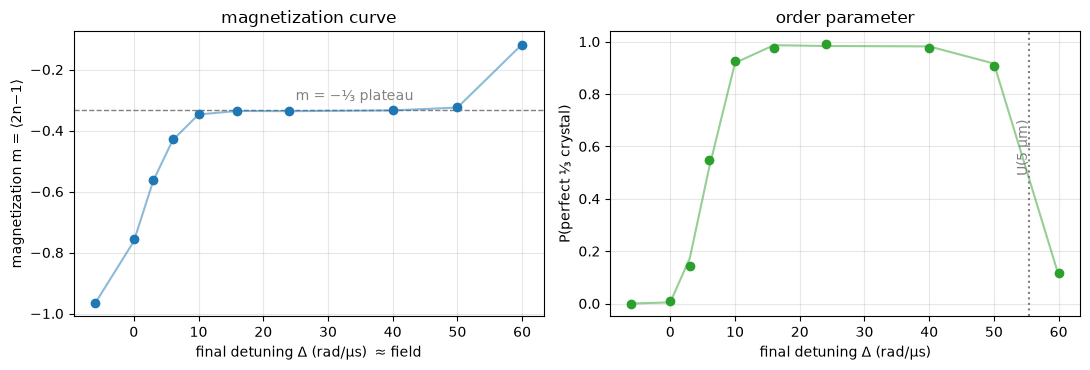

In [4]:
cset = set(crystals)
is_crystal = lambda b: tuple(i for i, x in enumerate(b) if x == "1") in cset
S = [{"n": float(densities(c).mean()), "m": magnetization(c), "crystal": prob(c, is_crystal),
      "n_i": densities(c).round(4).tolist()} for c in counts]
X = [{"n": float(densities(c).mean()), "m": magnetization(c), "crystal": prob(c, is_crystal)} for c in exact]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].axhline(-1 / 3, ls="--", color="gray", lw=1); ax[0].text(25, -0.30, "m = −⅓ plateau", color="gray")
ax[0].plot(DELTA_END, [x["m"] for x in X], "-", alpha=.5, color="C0")
ax[0].plot(DELTA_END, [s["m"] for s in S], "o", color="C0")
ax[0].set(xlabel="final detuning Δ (rad/µs)  ≈ field", ylabel="magnetization m = ⟨2n−1⟩", title="magnetization curve")
ax[1].plot(DELTA_END, [x["crystal"] for x in X], "-", alpha=.5, color="C2")
ax[1].plot(DELTA_END, [s["crystal"] for s in S], "o", color="C2")
ax[1].axvline(interaction(5), ls=":", color="gray"); ax[1].text(interaction(5) - 2, .5, "U(5 µm)", rotation=90, color="gray")
ax[1].set(xlabel="final detuning Δ (rad/µs)", ylabel="P(perfect ⅓ crystal)", title="order parameter")
for a in ax: a.grid(alpha=.3)
plt.tight_layout()

**What to see.** The magnetization climbs from −1 and then **locks at −⅓** for
Δ ≈ 10–50 rad/µs, where nearly every shot is a perfect ⅓ crystal. The plateau ends when
Δ approaches the nearest-neighbour interaction U(5 µm) ≈ 55 rad/µs: it then pays to put two
neighbours in the Rydberg state, and the crystal melts towards the next plateau. Real
TmMgGaO₄ shows the mirror-image plateau at m = +⅓ in a magnetic field. It is the same model;
only the sign of the field differs.

In [5]:
snap_i = DELTA_END.index(24)
result = {"chapter": 3, "traps": TRAPS, "edges": E, "mis": k, "n_crystals": len(crystals),
          "omega": OMEGA, "delta_start": DELTA_START, "delta_end": DELTA_END, "target": TARGET,
          "shots": SHOTS, "emu": S, "exact": X,
          "snapshots": [b for b, _ in top(counts[snap_i], 6)],
          "snapshots_melted": [b for b, _ in top(counts[-1], 4)]}
json.dump(result, open(ROOT / "results" / "03_magnet.json", "w"), indent=1)
print({d: round(s["crystal"], 2) for d, s in zip(DELTA_END, S)})

{-6: 0.0, 0: 0.01, 3: 0.14, 6: 0.55, 10: 0.93, 16: 0.98, 24: 0.99, 40: 0.98, 50: 0.91, 60: 0.12}


### Going bigger

12 atoms is the free emulator's limit. The same model at **49 atoms** (7×7, on the 217-trap
layout) needs the tensor-network emulator `pasqal:pasqal:sim:emu-mps` (billed per minute),
or the QPU itself. A 49-atom magnetization sweep run this way through qBraid is shown on the
project page. Swap `TRAPS` for a 217-trap register (`layout_register(ids, n_traps=217)`;
layouts above 60 traps must be 35–55% filled) and change `EMULATOR`.

## Run it on the QPU

Everything above ran on the free emulator. The same sequences run unchanged on FRESNEL_CAN1.
QPU time is billed per minute and jobs wait in Pasqal's queue (hours to days), so:

1. Check the estimate (credits; 1 credit = USD 0.01). It is based on ~1.2 s of QPU time per shot.
2. Set `CONFIRM_QPU = True` and run the cell. It submits and prints the job IDs; it does not wait.
3. Come back later: `qbraid jobs get <id>`, or the Lab's **Quantum Jobs** panel.

In [6]:
CONFIRM_QPU = False
QPU_SHOTS = 50
QPU_DELTAS = [24, 60]          # on the plateau, and past it
print(qpu_estimate(QPU_SHOTS, n_jobs=len(QPU_DELTAS)))
if CONFIRM_QPU:
    jobs = [submit(adiabatic_sweep(reg, OMEGA, DELTA_START, d, duration=5000), "qpu", QPU_SHOTS,
                   confirm_qpu=True) for d in QPU_DELTAS]
    print("QPU job IDs:", *[j.id for j in jobs], sep="\n  ")

{'credits_per_minute': 6358.0, 'est_qpu_seconds': 120.0, 'est_credits': 12716.0, 'est_usd': 127.16}
